# Chapter 8 — Tree-Based Algorithms and Ensemble Methods
**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Environment:** Google Colab / Jupyter Notebook

This notebook covers the chapter's main recipes: decision trees, random forests and bagging, gradient boosting, hyperparameter tuning, and comparing ensemble methods.

## 1. Theory: trees and ensembles

A decision tree recursively splits data into groups that are more homogeneous with respect to the target. Trees are intuitive but can overfit if they grow too complex.

- **Bagging / random forests:** fit trees on randomized samples and features, then aggregate their predictions; this often reduces variance.
- **Gradient boosting:** build trees sequentially, with later trees correcting errors made by the current ensemble.
- **Stacking:** train a final estimator to combine predictions from different base estimators.

Useful complexity controls include `max_depth`, `min_samples_leaf`, and the number of trees or boosting stages.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
RANDOM_STATE = 42

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print("Training:", X_train.shape, "| Test:", X_test.shape)

Training: (105, 4) | Test: (45, 4)


## 2. Introduction to decision trees

Decision tree accuracy: 0.978
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



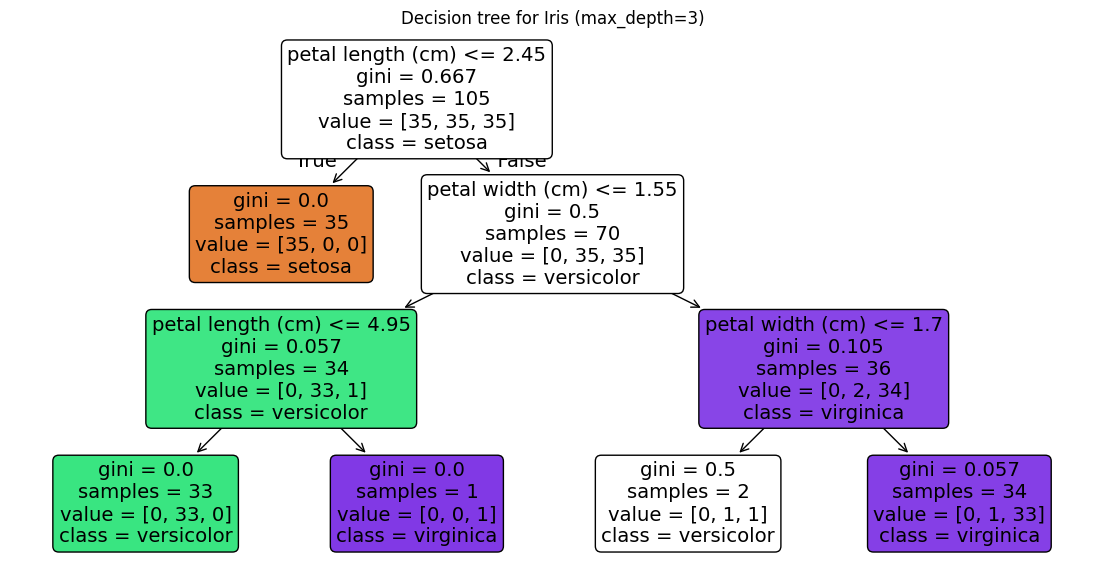

In [2]:
tree = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=3)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print(f"Decision tree accuracy: {accuracy_score(y_test, tree_pred):.3f}")
print(classification_report(y_test, tree_pred, target_names=iris.target_names))
plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True)
plt.title("Decision tree for Iris (max_depth=3)")
plt.show()

**Interpretation:** internal nodes test feature conditions and leaf nodes provide predictions. Limiting depth improves readability and can reduce overfitting. A deeper tree can fit training data more closely without necessarily generalizing better.

## 3. Random forests and bagging

Random forest accuracy: 0.889


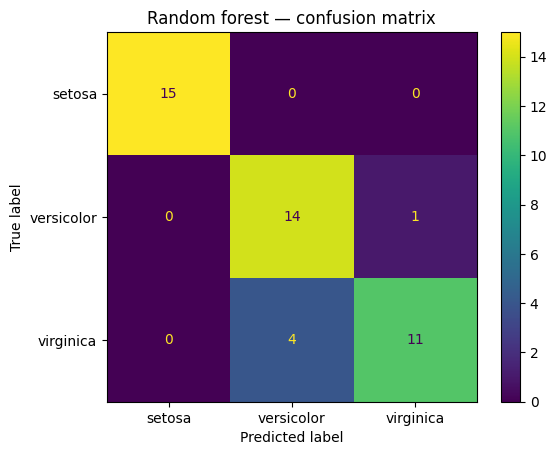

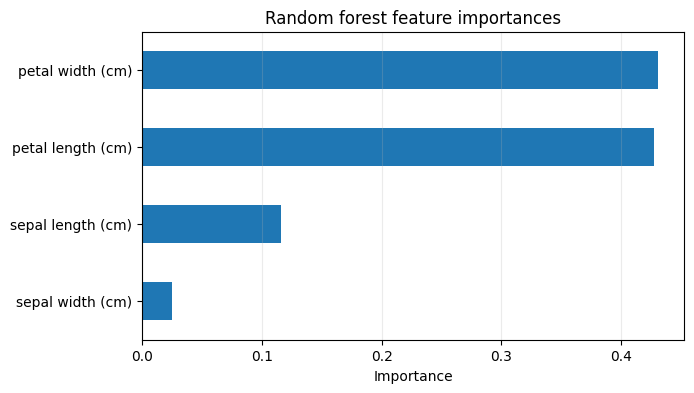

In [3]:
forest = RandomForestClassifier(n_estimators=250, max_features="sqrt",
                                random_state=RANDOM_STATE)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
print(f"Random forest accuracy: {accuracy_score(y_test, forest_pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, forest_pred, display_labels=iris.target_names)
plt.title("Random forest — confusion matrix")
plt.show()

importance = pd.Series(forest.feature_importances_, index=iris.feature_names).sort_values()
importance.plot(kind="barh", figsize=(7, 4))
plt.title("Random forest feature importances")
plt.xlabel("Importance")
plt.grid(axis="x", alpha=0.25)
plt.show()

Random forests aggregate many randomized trees. Feature importance is useful diagnostically, but it does not prove a feature causes the target; correlated features can affect importance estimates.

## 4. Gradient boosting machines

In [4]:
gbm = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                 max_depth=2, random_state=RANDOM_STATE)
gbm.fit(X_train, y_train)
gbm_pred = gbm.predict(X_test)
print(f"Gradient boosting accuracy: {accuracy_score(y_test, gbm_pred):.3f}")
print(classification_report(y_test, gbm_pred, target_names=iris.target_names))

Gradient boosting accuracy: 0.911
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



Boosting adds models sequentially to improve the ensemble. The learning rate controls each stage's contribution; smaller rates often require more estimators. Excessive complexity can still overfit, so use validation.

## 5. Hyperparameter tuning for trees and ensembles

In [5]:
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [100, 250], "max_depth": [None, 3, 5],
     "min_samples_leaf": [1, 2, 4]},
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
print("Best random forest parameters:", rf_search.best_params_)
print(f"Best mean CV accuracy: {rf_search.best_score_:.3f}")
rf_tuned_pred = rf_search.best_estimator_.predict(X_test)
print(f"Tuned forest test accuracy: {accuracy_score(y_test, rf_tuned_pred):.3f}")

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best random forest parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Best mean CV accuracy: 0.962
Tuned forest test accuracy: 0.889


## 6. Comparing ensemble methods and stacking

In [6]:
stack = StackingClassifier(
    estimators=[
        ("forest", RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE)),
        ("gbm", GradientBoostingClassifier(random_state=RANDOM_STATE)),
        ("tree", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5
)
stack.fit(X_train, y_train)
stack_pred = stack.predict(X_test)
comparison = pd.DataFrame([
    {"Model": "Decision tree", "Test accuracy": accuracy_score(y_test, tree_pred)},
    {"Model": "Random forest", "Test accuracy": accuracy_score(y_test, forest_pred)},
    {"Model": "Gradient boosting", "Test accuracy": accuracy_score(y_test, gbm_pred)},
    {"Model": "Tuned random forest", "Test accuracy": accuracy_score(y_test, rf_tuned_pred)},
    {"Model": "Stacking", "Test accuracy": accuracy_score(y_test, stack_pred)}
]).set_index("Model").sort_values("Test accuracy", ascending=False)
display(comparison.round(3))

,Test accuracy
Model,
Decision tree,0.978
Gradient boosting,0.911
Stacking,0.911
Random forest,0.889
Tuned random forest,0.889


**Interpretation:** forests average randomized trees, boosting learns sequentially from errors, and stacking learns how to combine different base estimators. The best method depends on the dataset and evaluation setup; ensembles do not always outperform a single tree on every test set.

## 7. Hands-on exercises

1. Compare decision trees with `max_depth=None`, `3`, and `5`.
2. Increase the random forest's `n_estimators` and compare results and runtime.
3. Tune `learning_rate` and `n_estimators` for gradient boosting.
4. Compare feature importances from a decision tree and random forest.
5. Explain how bagging differs from boosting and stacking.

## 8. Chapter summary

- Decision trees recursively split features and are interpretable, but can overfit.
- Random forests aggregate randomized trees to reduce variance.
- Gradient boosting builds trees sequentially to improve predictions.
- Stacking combines different base estimators through a final estimator.
- Tune complexity with cross-validation and use the test set for final evaluation.